In [1]:
# Let us use GraphST vertical version
import os
import torch
import pandas as pd
import scanpy as sc
from sklearn import metrics
import multiprocessing as mp
import matplotlib.pyplot as plt

/media/sda/wenjinma/envs/GraphST/lib/python3.8/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
from GraphST import GraphST

In [15]:
# Run device, by default, the package is implemented on 'cpu'. We recommend using GPU.
device = torch.device('cpu')

# the location of R, which is necessary for mclust algorithm. Please replace it with local R installation path
os.environ['R_HOME'] = '/media/sda/wenjinma/envs/GraphST/bin/R'

In [18]:
adata = sc.read_h5ad('data/mouse_breast_cancer_sample1_section1&2.h5ad')
adata.var_names_make_unique()

In [19]:
adata.obsm['spatial']

array([[10921,  4532],
       [12431, 12710],
       [ 9686, 13684],
       ...,
       [ 7391, 13028],
       [ 7724, 10762],
       [ 8962,  9411]])

In [20]:
adata.obs['data']

AAACAAGTATCTCCCA-11    S1
AAACACCAATAACTGC-11    S1
AAACAGCTTTCAGAAG-11    S1
AAACAGGGTCTATATT-11    S1
AAACCGGGTAGGTACC-11    S1
                       ..
TTGTGTATGCCACCAA-13    S3
TTGTGTTTCCCGAAAG-13    S3
TTGTTAGCAAATTCGA-13    S3
TTGTTCAGTGTGCTAC-13    S3
TTGTTGTGTGTCAAGA-13    S3
Name: data, Length: 3818, dtype: category
Categories (2, object): ['S1', 'S3']

Text(0.5, 1.0, 'Aligned image')

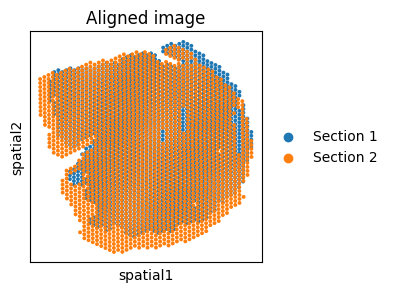

In [10]:
plt.rcParams["figure.figsize"] = (3, 3)
adata.obsm['spatial'][:, 1] = -1*adata.obsm['spatial'][:, 1]
adata.obs['data'].replace({'S1':'Section 1', 'S3':'Section 2'}, inplace=True)
ax = sc.pl.embedding(adata, basis='spatial',
                color='data',
                show=False)
ax.set_title('Aligned image')
#ax.axis('off')

In [16]:
model = GraphST.GraphST(adata, device=device)

# run model
adata = model.train()

Begin to train ST data...


100%|██████████| 600/600 [04:41<00:00,  2.13it/s]

Optimization finished for ST data!


In [22]:
import numpy as np
import anndata
import random
## check with our simulation data
seed=1234
base_dir = "/media/sda/wenjinma"
data_dir = base_dir+os.sep+"data/spatial_simulation_brain/666/10_50"
adata = anndata.read_h5ad(data_dir+os.sep+'adata.h5ad')
sampled_idx = random.sample(range(adata.shape[0]), 3000*3)
adata = adata[sampled_idx].copy()

In [28]:
adata.obs.rename(columns={'x_coor': 'pixel_x', 'y_coor': 'pixel_y', 'label': 'annotation'}, inplace=True)
loc = np.array(adata.obs[['pixel_x', 'pixel_y']]).astype('float64')
adata.obs['timepoint_numeric'] = adata.obs['timepoint'].astype('category').cat.codes
adata.obsm['spatial'] = loc
adata.obs['data'] = adata.obs['timepoint']

Text(0.5, 1.0, 'Aligned image')

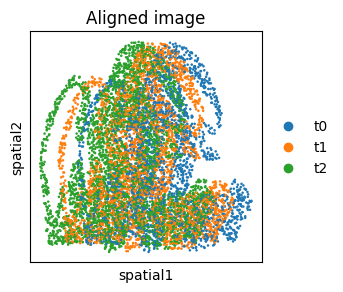

In [31]:
plt.rcParams["figure.figsize"] = (3, 3)
# adata.obsm['spatial'][:, 1] = -1*adata.obsm['spatial'][:, 1]
ax = sc.pl.embedding(adata, basis='spatial',
                color='data',
                show=False)
ax.set_title('Aligned image')

In [32]:
model = GraphST.GraphST(adata, device=device)

# run model
adata = model.train()

Begin to train ST data...


100%|██████████| 600/600 [17:34<00:00,  1.76s/it]


Optimization finished for ST data!


In [36]:
from GraphST.utils import clustering
n_clusters = 10
from GraphST.utils import clustering
clustering(adata, n_clusters, method='louvain', start=0.1, end=2.0, increment=0.01)

Searching resolution...
resolution=1.989999999999999, cluster number=17
resolution=1.979999999999999, cluster number=17
resolution=1.969999999999999, cluster number=17
resolution=1.959999999999999, cluster number=17
resolution=1.949999999999999, cluster number=17
resolution=1.939999999999999, cluster number=17
resolution=1.9299999999999993, cluster number=17
resolution=1.9199999999999993, cluster number=17
resolution=1.9099999999999993, cluster number=17
resolution=1.8999999999999992, cluster number=17
resolution=1.8899999999999992, cluster number=17
resolution=1.8799999999999992, cluster number=17
resolution=1.8699999999999992, cluster number=16
resolution=1.8599999999999992, cluster number=16
resolution=1.8499999999999992, cluster number=16
resolution=1.8399999999999992, cluster number=16
resolution=1.8299999999999992, cluster number=16
resolution=1.8199999999999992, cluster number=16
resolution=1.8099999999999992, cluster number=16
resolution=1.7999999999999992, cluster number=16
re

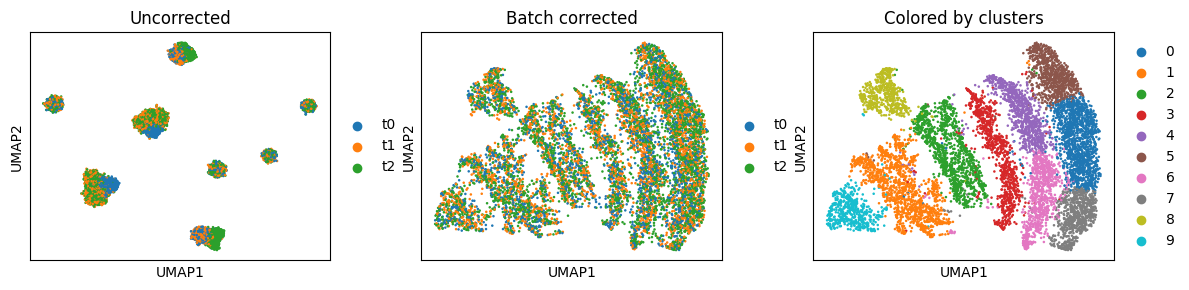

In [37]:
fig, ax_list = plt.subplots(1, 3, figsize=(12, 3))

### Plotting UMAP before batch effect correction
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)
sc.pp.pca(adata)

sc.pp.neighbors(adata, use_rep='X_pca', n_neighbors=10, n_pcs=40)
sc.tl.umap(adata)
sc.pl.umap(adata, color='data', title='Uncorrected',
                  ax = ax_list[0],
                  show=False)

### Plotting UMAP after batch effect correction
sc.pp.neighbors(adata, use_rep='emb', n_neighbors=10)
sc.tl.umap(adata)
sc.pl.umap(adata,
           color='data',
           ax=ax_list[1],
           title='Batch corrected',
           #legend_loc = 'bottom margin',
           show=False)

### Color by predicted domains
sc.pl.umap(adata, color='domain', ax=ax_list[2], title='Colored by clusters', show=False)

plt.tight_layout(w_pad=0.02)

<AxesSubplot:title={'center':'Colored by region'}, xlabel='UMAP1', ylabel='UMAP2'>

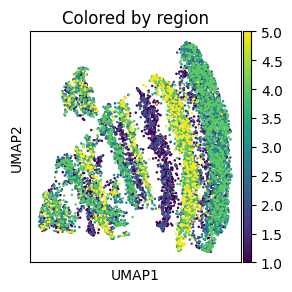

In [51]:
sc.pl.umap(adata, color='annotation', title='Colored by region', show=False)

<AxesSubplot:title={'center':'Colored by celltype'}, xlabel='UMAP1', ylabel='UMAP2'>

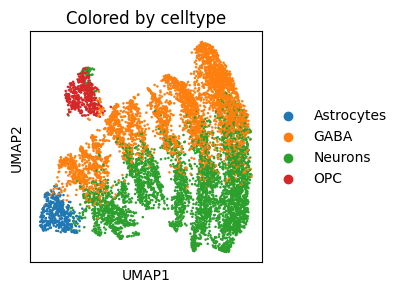

In [52]:
sc.pl.umap(adata, color='celltype', title='Colored by celltype', show=False)

In [40]:
adata.obsm['emb_pca'].shape # 9000x20

(9000, 20)

/tmp/ipykernel_28802/599381968.py:12: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  tp_adata.obs['kmeans'] = tp_kmeans.labels_.astype(str)


t1 Kmeans ARI: -0.002


/tmp/ipykernel_28802/599381968.py:12: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  tp_adata.obs['kmeans'] = tp_kmeans.labels_.astype(str)


t0 Kmeans ARI: -0.004


/tmp/ipykernel_28802/599381968.py:12: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  tp_adata.obs['kmeans'] = tp_kmeans.labels_.astype(str)


t2 Kmeans ARI: 0.004


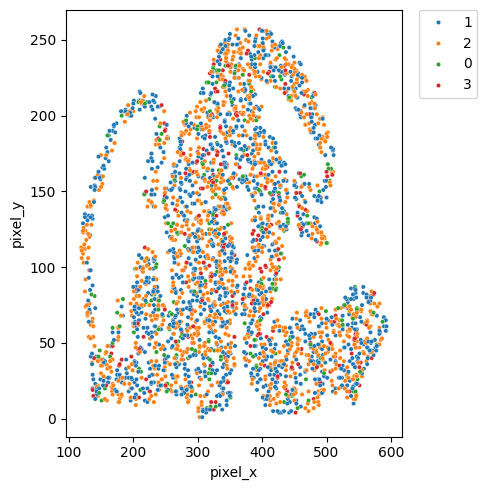

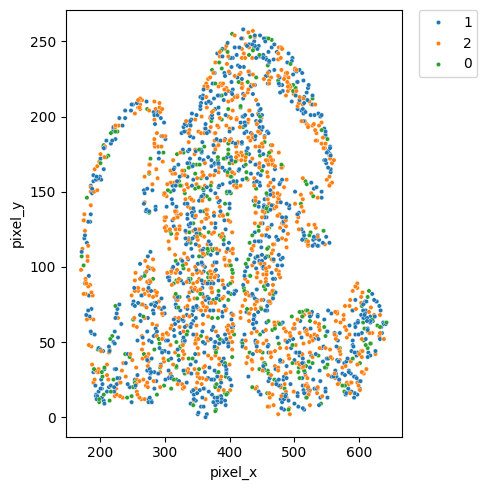

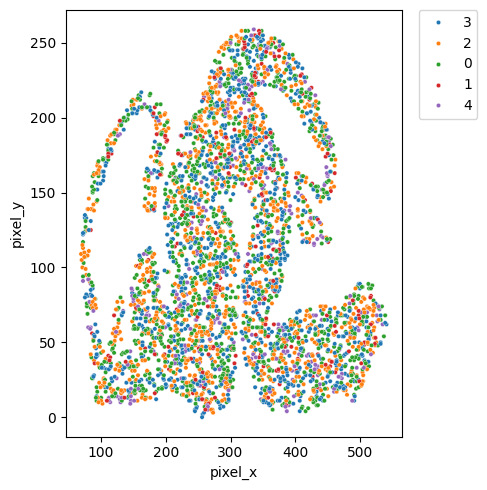

In [48]:
# separate according to timepoint and perform KMeans clustering
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import seaborn as sns

tp_kmeans_dict = dict()
for tp in set(adata.obs['timepoint']):
    tp_adata = adata[adata.obs['timepoint'] == tp]
    tp_emb = tp_adata.obsm['emb_pca']
    tp_kmeans = KMeans(n_clusters=len(set(tp_adata.obs['annotation'])), random_state=0).fit(tp_emb)
    tp_kmeans_dict[tp] = tp_kmeans
    tp_adata.obs['kmeans'] = tp_kmeans.labels_.astype(str)
    print('%s Kmeans ARI: %.3f' % (tp, adjusted_rand_score(tp_adata.obs['annotation'], tp_adata.obs['kmeans'])))
    plt.figure(figsize=(5,5))
    ax = sns.scatterplot(data=tp_adata.obs, x='pixel_x', y='pixel_y', hue='kmeans', s=10)
    plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
    plt.tight_layout()
    plt.savefig(str(tp)+'_Kmeans_separate_clustering.png')
    




In [46]:
tp_emb.shape

(3696, 20)

In [43]:
tp = 't0'
tp_idx = np.where(adata.obs['timepoint'] == tp)[0]
tp_idx
adata.obsm['emb_pca'][tp_idx]

array([[  8.930526  ,  -3.2294245 ,  -4.528259  , ...,   0.40530097,
         -0.89236337,  -1.0086043 ],
       [-12.378392  ,  -3.1378517 ,  -4.900507  , ...,  -0.7900363 ,
          0.441109  ,  -0.48271453],
       [-21.015339  ,   0.74571043,  -4.5874624 , ...,   0.19303565,
          0.08083148,   1.1546245 ],
       ...,
       [  9.316543  ,  13.9726095 ,  -7.134618  , ...,   0.02328336,
         -0.5173569 ,  -0.89187956],
       [ -8.332489  , -12.727793  ,  -1.9984763 , ...,  -0.24156614,
          1.4160384 ,  -1.4458133 ],
       [ 20.201998  ,  -1.8246701 ,  -1.1271157 , ...,  -0.0393021 ,
          1.0885984 ,   0.3329454 ]], dtype=float32)